In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.preprocessing import normalize
import scipy.cluster.hierarchy as shc
from sklearn.cluster import AgglomerativeClustering
from sklearn import decomposition
from scipy.spatial.distance import cdist

In [2]:
data = pd.read_excel("C:/Users/gus6e/OneDrive/Downloads/Amazon (1).xlsx")

data = data.rename(columns={data.columns[0]: "Cliente"})

columnas = list(data.columns[1:])

display(data.head())

print("Número de clientes:", len(data))
print("Variables de evaluación:", columnas)

,Cliente,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
0,Adam,205,3,345,235,24,23,26,21,17
1,Anna,9,15,315,33,25,4,42,215,28
2,Bernard,17,26,285,3,43,27,41,26,33
3,Edward,135,5,355,295,18,23,39,195,17
4,Emilia,3,45,48,39,34,46,225,34,43


Número de clientes: 100
Variables de evaluación: ['Velocidad Entrega', 'Precio', 'Durabilidad', 'Imagen Producto', 'Valor Educativo', 'Servicio Retorno', 'Tamano Paquete', 'Calidad Producto', 'Numero Estrellas']


In [3]:
data_scaled = normalize(data[columnas].astype(float))

data_scaled = pd.DataFrame(
    data_scaled,
    columns=columnas,
    index=data["Cliente"]
)

display(data_scaled.head())

,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
Cliente,,,,,,,,,
Adam,0.438263,0.006414,0.737565,0.502399,0.051309,0.049171,0.055585,0.044895,0.036344
Anna,0.023235,0.038725,0.813234,0.085196,0.064542,0.010327,0.108431,0.555065,0.072287
Bernard,0.057235,0.087535,0.959520,0.010100,0.144770,0.090902,0.138036,0.087535,0.111102
Edward,0.258856,0.009587,0.680696,0.565649,0.034514,0.044101,0.074781,0.373904,0.032597
Emilia,0.011975,0.179625,0.191600,0.155675,0.135717,0.183617,0.898127,0.135717,0.171642


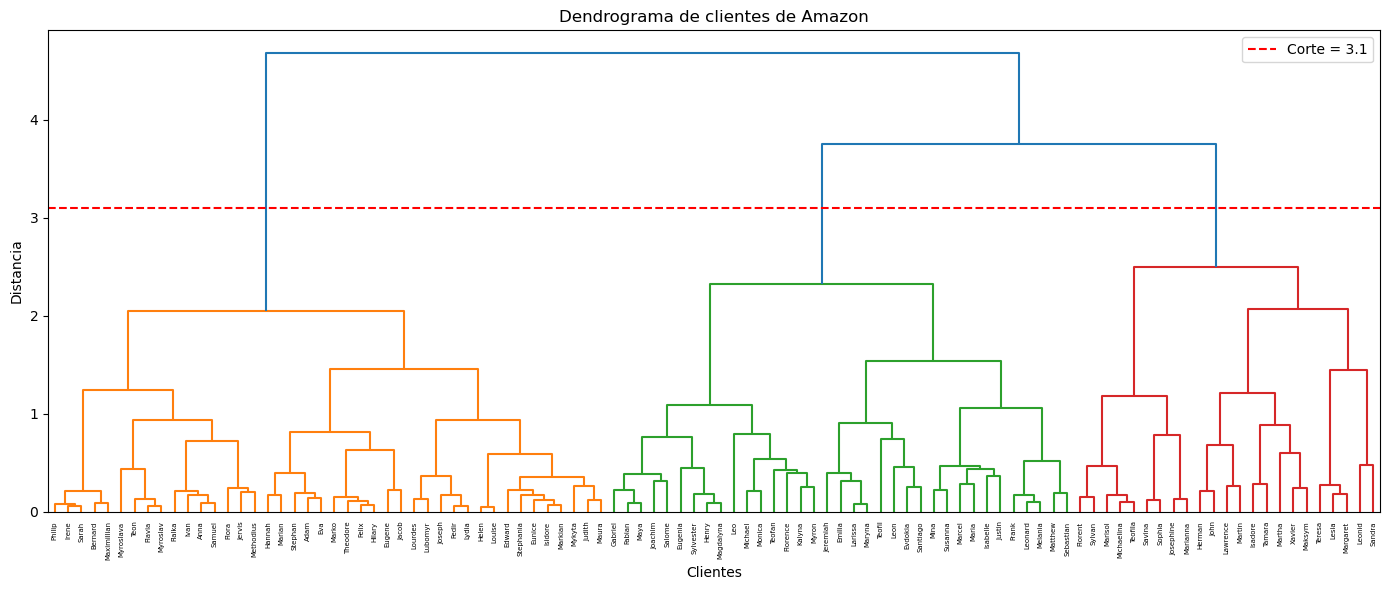

In [4]:
matriz_enlaces = shc.linkage(
    data_scaled,
    method="ward",
    metric="euclidean"
)

umbral = 3.1

plt.figure(figsize=(14, 6))

dend = shc.dendrogram(
    matriz_enlaces,
    labels=data["Cliente"].tolist(),
    leaf_rotation=90,
    leaf_font_size=5
)

plt.axhline(
    y=umbral,
    color="red",
    linestyle="--",
    label=f"Corte = {umbral}"
)

plt.title("Dendrograma de clientes de Amazon")
plt.xlabel("Clientes")
plt.ylabel("Distancia")

plt.legend()
plt.tight_layout()
plt.show()

In [5]:
print("Colores del dendrograma:")
print(set(dend["color_list"]))

num_clusters_optimo = int(
    (matriz_enlaces[:, 2] > umbral).sum() + 1
)

print("Número de clústeres:", num_clusters_optimo)

Colores del dendrograma:
{'C0', 'C1', 'C2', 'C3'}
Número de clústeres: 3


In [6]:
cluster = AgglomerativeClustering(
    n_clusters=num_clusters_optimo,
    metric="euclidean",
    linkage="ward"
)

grupos = cluster.fit_predict(data_scaled)

dataframe = pd.DataFrame({
    "Cliente": data["Cliente"],
    "grupo": grupos + 1
})

dataframe2 = pd.concat(
    [data, dataframe[["grupo"]]],
    axis=1
)

display(dataframe2.head())

print("Cantidad de clientes por grupo:")
display(dataframe2.groupby("grupo").size())

,Cliente,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas,grupo
0,Adam,205,3,345,235,24,23,26,21,17,2
1,Anna,9,15,315,33,25,4,42,215,28,2
2,Bernard,17,26,285,3,43,27,41,26,33,2
3,Edward,135,5,355,295,18,23,39,195,17,2
4,Emilia,3,45,48,39,34,46,225,34,43,3


Cantidad de clientes por grupo:


grupo
1    23
2    42
3    35
dtype: int64

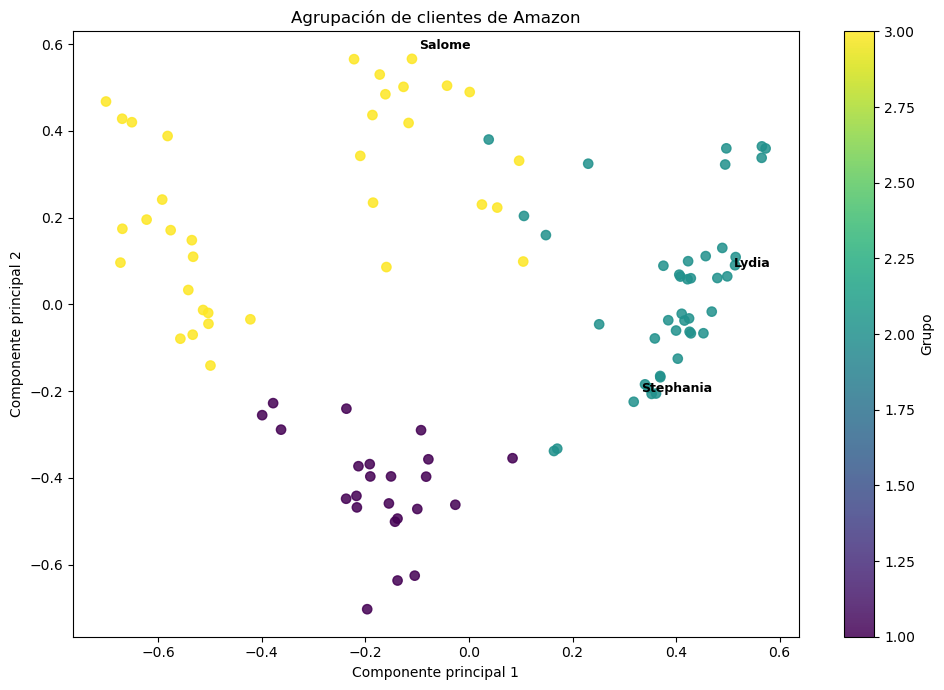

In [7]:
pca = decomposition.PCA(n_components=2)

campos = pca.fit_transform(data_scaled.values)

plt.figure(figsize=(10, 7))

sc = plt.scatter(
    campos[:, 0],
    campos[:, 1],
    c=grupos + 1,
    cmap="viridis",
    s=45,
    alpha=0.85
)

for nombre in ["Salome", "Stephania", "Lydia"]:
    i = data.index[data["Cliente"] == nombre][0]

    plt.annotate(
        nombre,
        (campos[i, 0], campos[i, 1]),
        xytext=(5, 7),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold"
    )

plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Agrupación de clientes de Amazon")

plt.colorbar(sc, label="Grupo")
plt.tight_layout()
plt.show()

In [8]:
clientes_objetivo = ["Salome", "Stephania", "Lydia"]

clientes_seleccionados = dataframe2[
    dataframe2["Cliente"].isin(clientes_objetivo)
]

display(clientes_seleccionados)

,Cliente,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas,grupo
54,Lydia,19,4,435,145,16,21,28,185,24,2
81,Salome,17,23,275,41,4,44,315,28,32,3
89,Stephania,215,125,465,315,34,4,37,305,45,2


In [9]:
for nombre in clientes_objetivo:

    grupo_cliente = dataframe2.loc[
        dataframe2["Cliente"] == nombre, "grupo"
    ].iloc[0]

    clientes_mismo_grupo = dataframe2[
        (dataframe2["grupo"] == grupo_cliente) &
        (dataframe2["Cliente"] != nombre)
    ]

    print(f"\nCliente: {nombre}")
    print(f"Pertenece al grupo: {grupo_cliente}")
    print("Otros clientes del mismo grupo:")

    display(clientes_mismo_grupo[["Cliente", "grupo"]])


Cliente: Salome
Pertenece al grupo: 3
Otros clientes del mismo grupo:


,Cliente,grupo
4,Emilia,3
5,Fabian,3
7,Frank,3
9,Gabriel,3
11,Henry,3
13,Isabelle,3
17,Eugenia,3
20,Evdokia,3
27,Florence,3
36,Jeremiah,3



Cliente: Stephania
Pertenece al grupo: 2
Otros clientes del mismo grupo:


,Cliente,grupo
0,Adam,2
1,Anna,2
2,Bernard,2
3,Edward,2
6,Philip,2
12,Irene,2
14,Isidore,2
15,Joseph,2
16,Eugene,2
18,Eunice,2



Cliente: Lydia
Pertenece al grupo: 2
Otros clientes del mismo grupo:


,Cliente,grupo
0,Adam,2
1,Anna,2
2,Bernard,2
3,Edward,2
6,Philip,2
12,Irene,2
14,Isidore,2
15,Joseph,2
16,Eugene,2
18,Eunice,2


In [12]:
distancias = cdist(
    data_scaled.to_numpy(),
    data_scaled.to_numpy(),
    metric="euclidean"
)

objetivos = {
    "Salomé": "Salome",
    "Stephanía": "Stephania",
    "Lydia": "Lydia"
}

recomendaciones = []

for nombre_visible, nombre_excel in objetivos.items():

    i = data.index[
        data["Cliente"] == nombre_excel
    ][0]

    candidatos = [
        j for j in range(len(data))
        if j != i and grupos[j] == grupos[i]
    ]

    mas_cercanos = sorted(
        candidatos,
        key=lambda j: distancias[i, j]
    )[:3]

    for puesto, j in enumerate(mas_cercanos, start=1):

        recomendaciones.append({
            "Cliente objetivo": nombre_visible,
            "Grupo": int(grupos[i] + 1),
            "Orden": puesto,
            "Cliente recomendado": data.loc[j, "Cliente"],
            "Distancia": round(float(distancias[i, j]), 4)
        })

resultado = pd.DataFrame(recomendaciones)

display(resultado)

,Cliente objetivo,Grupo,Orden,Cliente recomendado,Distancia
0,Salomé,3,1,Magdalyna,0.2405
1,Salomé,3,2,Fabian,0.2609
2,Salomé,3,3,Kalyna,0.2640
3,Stephanía,2,1,Isidore,0.1139
4,Stephanía,2,2,Markian,0.1228
5,Stephanía,2,3,Judith,0.1355
6,Lydia,2,1,Fedir,0.0561
7,Lydia,2,2,Joseph,0.1252
8,Lydia,2,3,Lourdes,0.2526


In [13]:
for cliente, tabla in resultado.groupby(
    "Cliente objetivo", sort=False
):

    grupo = tabla["Grupo"].iloc[0]

    nombres = ", ".join(
        tabla["Cliente recomendado"].tolist()
    )

    print(f"\nRecomendaciones para {cliente}:")
    print(f"Pertenece al clúster {grupo}.")

    print(
        f"Recomendaría a {cliente} considerar los productos "
        f"que compraron {nombres}, debido a que sus perfiles "
        f"de evaluación son similares y pertenecen "
        f"al mismo clúster."
    )


Recomendaciones para Salomé:
Pertenece al clúster 3.
Recomendaría a Salomé considerar los productos que compraron Magdalyna, Fabian, Kalyna, debido a que sus perfiles de evaluación son similares y pertenecen al mismo clúster.

Recomendaciones para Stephanía:
Pertenece al clúster 2.
Recomendaría a Stephanía considerar los productos que compraron Isidore, Markian, Judith, debido a que sus perfiles de evaluación son similares y pertenecen al mismo clúster.

Recomendaciones para Lydia:
Pertenece al clúster 2.
Recomendaría a Lydia considerar los productos que compraron Fedir, Joseph, Lourdes, debido a que sus perfiles de evaluación son similares y pertenecen al mismo clúster.
